# Causal activity bridge

[CORNETO](https://github.com/saezlab/corneto) solves a small
[CARNIVAL](https://saezlab.github.io/CARNIVAL/) signaling problem: it selects the
signed edges that connect a perturbed receptor to the measured transcription
factors. AnnNet then stores the selected edges, the node activities and a
solution slice next to the original prior network.

To run this notebook, create the environment from
[`causal-activity-bridge.yml`](environments/causal-activity-bridge.yml). See
[Reproduce a tutorial](index.md#reproduce-a-tutorial).

## Build the CORNETO prior and measurements

The prior network is a list of signed edges. The sample has one input, `rec2`,
and two measured outputs, `tf1` and `tf2`.

In [1]:
import annnet as an
import corneto as cn
from corneto.graph import Graph

pkn_tuples = [
    ('rec1', 1, 'a'),
    ('rec1', -1, 'b'),
    ('rec1', 1, 'f'),
    ('rec1', -1, 'c'),
    ('rec2', 1, 'b'),
    ('rec2', 1, 'tf2'),
    ('b', 1, 'g'),
    ('g', -1, 'd'),
    ('rec2', -1, 'd'),
    ('a', 1, 'c'),
    ('a', -1, 'd'),
    ('c', 1, 'd'),
    ('c', -1, 'e'),
    ('c', 1, 'tf3'),
    ('e', 1, 'a'),
    ('d', -1, 'c'),
    ('e', 1, 'tf1'),
    ('a', -1, 'tf1'),
    ('d', 1, 'tf2'),
    ('c', -1, 'tf2'),
    ('tf1', 1, 'tf2'),
    ('tf1', -1, 'rec2'),
    ('tf2', 1, 'rec1'),
    ('tf1', 1, 'f'),
]
corneto_graph = Graph.from_tuples(pkn_tuples)
samples = {
    'input_example': {
        'rec2': {'value': 1, 'mapping': 'node', 'role': 'input'},
        'tf1': {'value': -2, 'mapping': 'node', 'role': 'output'},
        'tf2': {'value': 1, 'mapping': 'node', 'role': 'output'},
    }
}
data = cn.Data.from_cdict(samples)

## Solve CARNIVAL and inspect the selected signal

The tables show the edges and the nodes with a non-zero activity in the
solution.

In [2]:
import numpy as np
import pandas as pd
import polars as pl
from corneto.methods.carnival import CarnivalFlow

model = CarnivalFlow(lambda_reg=1e-3)
problem = model.build_from_data(corneto_graph, data)
problem.solve(verbosity=0, solver='scipy')

edge_values = pd.DataFrame(
    problem.expr.edge_value.value,
    index=model.processed_graph.E,
    columns=['edge_activity'],
).astype(int)
node_values = pd.DataFrame(
    problem.expr.vertex_value.value,
    index=model.processed_graph.V,
    columns=['node_activity'],
).astype(int)
selected_idx = np.flatnonzero(problem.expr.edge_has_signal.value)

edge_rows = []
for edge_obj, row in edge_values.iterrows():
    source, target = edge_obj
    activity = int(row['edge_activity'])
    if activity == 0:
        continue
    edge_rows.append(
        {
            'edge': f'{", ".join(sorted(source)) or "(input)"} -> '
            f'{", ".join(sorted(target)) or "(output)"}',
            'activity': activity,
        }
    )

print('objective values:', [float(obj.value) for obj in problem.objectives])
display(pl.DataFrame(edge_rows))
display(
    pl.DataFrame(
        [
            {'node': str(node), 'activity': int(row['node_activity'])}
            for node, row in node_values.iterrows()
            if int(row['node_activity']) != 0
        ]
    )
)

Unreachable vertices for sample: 0
objective values: [0.0, 5.0]


edge,activity
str,i64
"""rec1 -> a""",1
"""rec2 -> tf2""",1
"""a -> tf1""",-1
"""tf2 -> rec1""",1
"""(input) -> rec2""",1


node,activity
str,i64
"""rec1""",1
"""a""",1
"""rec2""",1
"""tf2""",1
"""tf1""",-1


## CORNETO selected subgraph


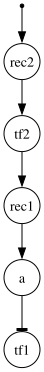

In [3]:
model.processed_graph.edge_subgraph(selected_idx).plot()

## Store the CORNETO result in AnnNet

Every prior edge gets an edge ID. The activities from the solution become
edge and node attributes, and the selected edges form the `corneto_signal`
slice.

In [4]:
anet = an.AnnNet(directed=True)
edge_ids_by_pair = {}
for source, sign, target in pkn_tuples:
    effect = 'activates' if sign > 0 else 'inhibits'
    edge_id = f'{source}_{effect}_{target}'
    anet.add_edges(
        source,
        target,
        edge_id=edge_id,
        weight=abs(sign),
        interaction=sign,
        effect=effect,
    )
    edge_ids_by_pair[(source, target)] = edge_id

selected_edges = []
for edge_obj, row in edge_values.iterrows():
    source, target = edge_obj
    activity = int(row['edge_activity'])
    # Skip inactive edges and the edges from the input and to the outputs
    if activity == 0 or len(source) != 1 or len(target) != 1:
        continue
    edge_id = edge_ids_by_pair[(next(iter(source)), next(iter(target)))]
    selected_edges.append(edge_id)
    anet.attrs.update('edges', {edge_id: {'corneto_activity': activity}})

anet.attrs.update(
    'nodes',
    {
        str(node): {'corneto_activity': int(row['node_activity'])}
        for node, row in node_values.iterrows()
    },
)

anet.slices.add('corneto_signal')
anet.slices.add_edges('corneto_signal', selected_edges)

selected_labels = {
    row['edge_id']: f'{row["source"]} -> {row["target"]}'
    for row in anet.attrs.table('edges', derived=True).iter_rows(named=True)
}
print('AnnNet shape:', anet.shape)
print('selected edges:', [selected_labels[eid] for eid in sorted(selected_edges)])
anet.attrs.table('edges', derived=True).select(
    ['edge_id', 'source', 'target', 'effect', 'corneto_activity']
)

AnnNet shape: (12, 24)
selected edges: ['a -> tf1', 'rec1 -> a', 'rec2 -> tf2', 'tf2 -> rec1']


edge_id,source,target,effect,corneto_activity
str,str,str,str,i64
"""rec1_activates_a""","""rec1""","""a""","""activates""",1
"""rec1_inhibits_b""","""rec1""","""b""","""inhibits""",null
"""rec1_activates_f""","""rec1""","""f""","""activates""",null
"""rec1_inhibits_c""","""rec1""","""c""","""inhibits""",null
"""rec2_activates_b""","""rec2""","""b""","""activates""",null
…,…,…,…,…
"""c_inhibits_tf2""","""c""","""tf2""","""inhibits""",null
"""tf1_activates_tf2""","""tf1""","""tf2""","""activates""",null
"""tf1_inhibits_rec2""","""tf1""","""rec2""","""inhibits""",null


## AnnNet solution slice

`subgraph_from_slice` makes a new graph that contains only the selected
edges.

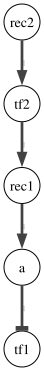

In [5]:
from annnet.utils import plotting

solution_anet = anet.subgraph_from_slice('corneto_signal')
plotting.plot(solution_anet, backend='graphviz', show_edge_labels=True)

The notebook can solve the CORNETO problem again at any time. AnnNet keeps the
result attached to a graph object that you can slice, annotate, export, or
combine with other analyses.